# Horse Grimace Region Dataset Prep

Prepare the public **Automatic Pain Assessment in Horses** Mendeley dataset for an OpenFARM horse grimace / facial-region benchmark.

The source is region-shaped rather than whole-face-shaped: labelled rows are crops of ears, eyes, and mouth/nostrils scored as pain not present, moderately present, or obviously present. This notebook keeps that shape and builds animal-heldout splits.


In [1]:
#@title Setup dependencies and imports
!pip -q install datasets huggingface_hub pillow requests scikit-learn matplotlib seaborn

import io
import json
import os
import re
import shutil
from collections import Counter
from contextlib import nullcontext
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from datasets import ClassLabel, Dataset, DatasetDict, Image
from huggingface_hub import HfApi, login
from IPython.display import display
from PIL import Image as PILImage, ImageDraw
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid")


In [2]:
#@title Configuration
WORK_DIR = "/content/openfarm_horse_grimace" #@param {type:"string"}
OUTPUT_REPO_ID = "oliveirabruno01/openfarm-horse-grimace-region" #@param {type:"string"}
SEED = 42 #@param {type:"integer"}

HELDOUT_HORSES = "6,7" #@param {type:"string"}
BALANCE_BY_REGION_SCORE = True #@param {type:"boolean"}
MAX_TRAIN_PER_REGION_SCORE = -1 #@param {type:"integer"}
MAX_TEST_PER_REGION_SCORE = -1 #@param {type:"integer"}

PUSH_TO_HUB = True #@param {type:"boolean"}
HF_TOKEN_SECRET = "HF_TOKEN" #@param {type:"string"}

ROOT = Path(WORK_DIR)
RAW_DIR = ROOT / "raw"
PREPARED_DIR = ROOT / "prepared"
MEDIA_DIR = PREPARED_DIR / "images"
REPORT_DIR = PREPARED_DIR / "reports"
for path in [RAW_DIR, PREPARED_DIR, MEDIA_DIR, REPORT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

RECORD_ID = "t8rtzcgwxm"
SOURCE_URL = "https://data.mendeley.com/datasets/t8rtzcgwxm"
SOURCE_DOI = "10.17632/t8rtzcgwxm.3"
PAPER_DOI = "10.1371/journal.pone.0258672"
LICENSE = "cc-by-4.0"
SCORE_LABELS = ["not_present", "moderately_present", "obviously_present"]
REGION_LABELS = ["ears", "eyes", "mouth_nostrils"]


In [3]:
#@title Load and verify Mendeley metadata

def request_json(url: str) -> dict:
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    return response.json()

record = request_json(f"https://data.mendeley.com/public-api/datasets/{RECORD_ID}")
source_manifest = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_url": SOURCE_URL,
    "source_doi": SOURCE_DOI,
    "paper_doi": PAPER_DOI,
    "license": record.get("data_licence", {}).get("short_name", "CC BY 4.0"),
    "record_version": record.get("version"),
    "record_size_bytes": record.get("size"),
    "file_count": len(record.get("files", [])),
}
print(json.dumps(source_manifest, indent=2))


{
  "generated_at": "2026-05-18T07:12:03.370126+00:00",
  "source_url": "https://data.mendeley.com/datasets/t8rtzcgwxm",
  "source_doi": "10.17632/t8rtzcgwxm.3",
  "paper_doi": "10.1371/journal.pone.0258672",
  "license": "CC BY 4.0",
  "record_version": 3,
  "record_size_bytes": 96291812,
  "file_count": 5330
}


In [4]:
#@title Parse region-score labels from source file manifest
REGION_MAP = {
    "A": ("ears", "position_of_ears"),
    "B": ("eyes", "orbital_tightening_and_eye_area"),
    "C": ("mouth_nostrils", "mouth_chin_nostrils_and_profile"),
}
SCORE_MAP = {
    0: "not_present",
    1: "moderately_present",
    2: "obviously_present",
}

records = []
skipped_images = Counter()
for source_file in record["files"]:
    filename = source_file["filename"]
    content = source_file.get("content_details", {})
    content_type = content.get("content_type", "")
    match = re.match(r"M(?P<horse>\d+)_(?P<region>[ABC])(?P<score>[012])", filename)
    if not match:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")) or content_type.startswith("image/"):
            skipped_images[filename] += 1
        continue

    region_code = match.group("region")
    pain_score = int(match.group("score"))
    face_region, face_region_note = REGION_MAP[region_code]
    records.append({
        "image_source_url": content["download_url"],
        "horse_id": f"M{match.group('horse')}",
        "face_region": face_region,
        "face_region_code": region_code,
        "face_region_note": face_region_note,
        "pain_score": pain_score,
        "pain_label": SCORE_MAP[pain_score],
        "binary_pain_label": "pain" if pain_score > 0 else "no_pain",
        "source_filename": filename,
        "source_file_id": source_file["id"],
        "source_sha256": content.get("sha256_hash", ""),
        "download_size": source_file.get("size"),
        "source_url": SOURCE_URL,
        "source_doi": SOURCE_DOI,
        "source_paper_doi": PAPER_DOI,
        "license": LICENSE,
    })

metadata_df = pd.DataFrame(records)
print("labelled region rows:", len(metadata_df))
print("skipped unlabelled image files:", sum(skipped_images.values()), dict(skipped_images.most_common(8)))
display(metadata_df.groupby(["face_region", "pain_label"]).size().reset_index(name="n"))
display(metadata_df.groupby(["horse_id", "face_region"]).size().reset_index(name="n"))


labelled region rows: 4847
skipped unlabelled image files: 480 {'Boca.jpg.jpg': 120, 'Foto.jpg.jpg': 120, 'Olho.jpg.jpg': 120, 'Orelha.jpg.jpg': 120}


,face_region,pain_label,n
0,ears,moderately_present,201
1,ears,not_present,1991
2,ears,obviously_present,185
3,eyes,moderately_present,488
4,eyes,not_present,477
5,eyes,obviously_present,471
6,mouth_nostrils,moderately_present,393
7,mouth_nostrils,not_present,505
8,mouth_nostrils,obviously_present,136


,horse_id,face_region,n
0,M1,ears,704
1,M1,eyes,522
2,M1,mouth_nostrils,506
3,M2,ears,312
4,M2,eyes,114
5,M2,mouth_nostrils,28
6,M3,ears,134
7,M3,eyes,60
8,M3,mouth_nostrils,63
9,M4,ears,182


download audit thumbnails:   0%|          | 0/18 [00:00<?, ?it/s]

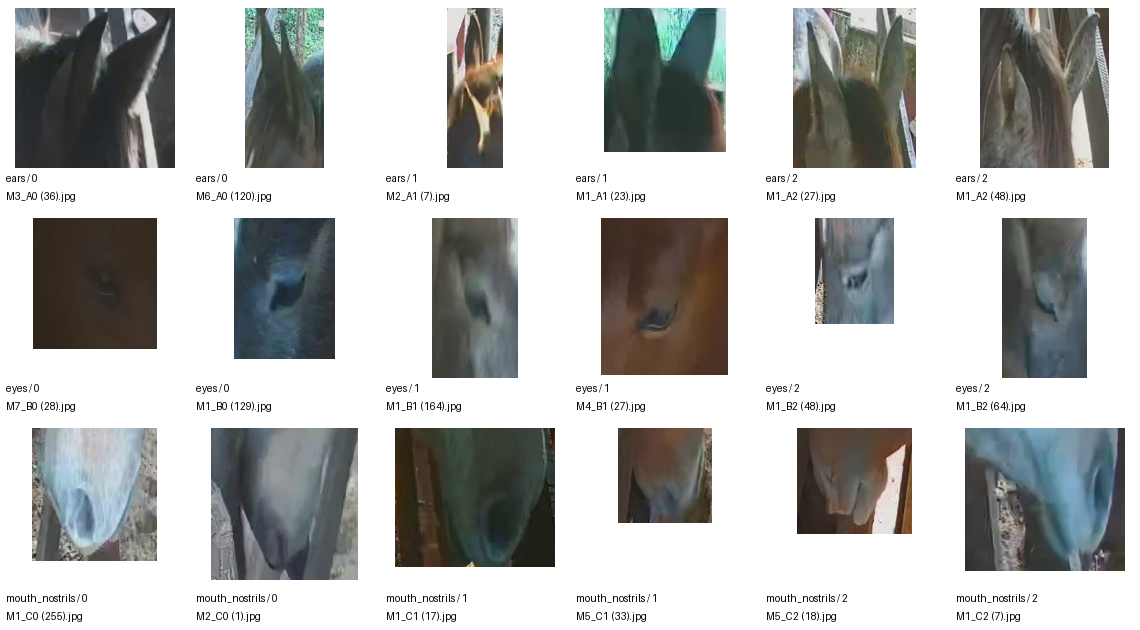

saved: /content/openfarm_horse_grimace/prepared/reports/horse_region_score_examples.jpg


In [5]:
#@title Visual audit: region-score examples
sample_rows = []
for (region, score), group in metadata_df.groupby(["face_region", "pain_score"]):
    sample_rows.extend(group.sample(n=min(2, len(group)), random_state=SEED).to_dict("records"))

thumbs = []
for row in tqdm(sample_rows, desc="download audit thumbnails"):
    response = requests.get(row["image_source_url"], timeout=60)
    response.raise_for_status()
    image = PILImage.open(io.BytesIO(response.content)).convert("RGB")
    image.thumbnail((160, 160))
    canvas = PILImage.new("RGB", (190, 210), "white")
    canvas.paste(image, ((190 - image.width) // 2, 8))
    draw = ImageDraw.Draw(canvas)
    draw.text((6, 172), f"{row['face_region']} / {row['pain_score']}", fill=(0, 0, 0))
    draw.text((6, 190), row["source_filename"][:28], fill=(0, 0, 0))
    thumbs.append(canvas)

cols = 6
sheet = PILImage.new("RGB", (cols * 190, int(np.ceil(len(thumbs) / cols)) * 210), (245, 245, 245))
for i, thumb in enumerate(thumbs):
    sheet.paste(thumb, ((i % cols) * 190, (i // cols) * 210))
display(sheet)
audit_path = REPORT_DIR / "horse_region_score_examples.jpg"
sheet.save(audit_path, quality=92)
print("saved:", audit_path)


In [6]:
#@title Build animal-heldout train/test views

def balanced_sample(frame: pd.DataFrame, group_cols: list[str], max_per_group: int, seed: int) -> pd.DataFrame:
    sizes = frame.groupby(group_cols).size()
    n = int(sizes.min())
    if max_per_group and max_per_group > 0:
        n = min(n, int(max_per_group))
    return (
        frame.groupby(group_cols, group_keys=False)
        .sample(n=n, random_state=seed)
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )

heldout_horses = {f"M{x.strip().removeprefix('M')}" for x in HELDOUT_HORSES.split(",") if x.strip()}
if not heldout_horses:
    raise ValueError("HELDOUT_HORSES must contain at least one horse id, for example '6,7'.")

train_raw_df = metadata_df[~metadata_df["horse_id"].isin(heldout_horses)].copy().reset_index(drop=True)
test_raw_df = metadata_df[metadata_df["horse_id"].isin(heldout_horses)].copy().reset_index(drop=True)

if BALANCE_BY_REGION_SCORE:
    train_df = balanced_sample(train_raw_df, ["face_region", "pain_score"], MAX_TRAIN_PER_REGION_SCORE, SEED)
    test_df = balanced_sample(test_raw_df, ["face_region", "pain_score"], MAX_TEST_PER_REGION_SCORE, SEED)
else:
    train_df = train_raw_df.copy()
    test_df = test_raw_df.copy()

split_frames = {
    "train": train_df,
    "test": test_df,
    "train_raw": train_raw_df,
    "test_raw": test_raw_df,
}

print("heldout horses:", sorted(heldout_horses))
for split_name, frame in split_frames.items():
    print(split_name, len(frame), Counter(zip(frame["face_region"], frame["pain_score"])))


heldout horses: ['M6', 'M7']
train 945 Counter({('mouth_nostrils', 2): 105, ('eyes', 0): 105, ('ears', 2): 105, ('ears', 0): 105, ('ears', 1): 105, ('eyes', 1): 105, ('mouth_nostrils', 0): 105, ('eyes', 2): 105, ('mouth_nostrils', 1): 105})
test 279 Counter({('ears', 0): 31, ('eyes', 1): 31, ('mouth_nostrils', 0): 31, ('mouth_nostrils', 2): 31, ('mouth_nostrils', 1): 31, ('eyes', 0): 31, ('ears', 2): 31, ('ears', 1): 31, ('eyes', 2): 31})
train_raw 3931 Counter({('ears', 0): 1646, ('mouth_nostrils', 0): 451, ('eyes', 1): 390, ('eyes', 0): 388, ('eyes', 2): 357, ('mouth_nostrils', 1): 315, ('ears', 1): 156, ('ears', 2): 123, ('mouth_nostrils', 2): 105})
test_raw 916 Counter({('ears', 0): 345, ('eyes', 2): 114, ('eyes', 1): 98, ('eyes', 0): 89, ('mouth_nostrils', 1): 78, ('ears', 2): 62, ('mouth_nostrils', 0): 54, ('ears', 1): 45, ('mouth_nostrils', 2): 31})


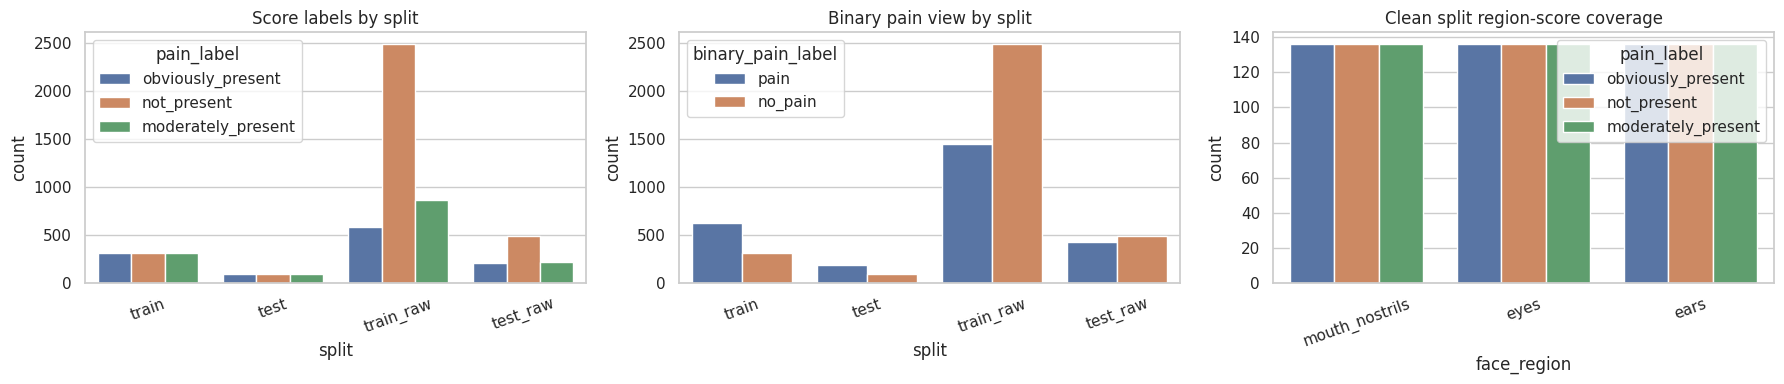

saved: /content/openfarm_horse_grimace/prepared/reports/horse_split_audit.png


In [7]:
#@title Split visual audit
plot_rows = []
for split_name, frame in split_frames.items():
    temp = frame.copy()
    temp["split"] = split_name
    plot_rows.append(temp)
plot_df = pd.concat(plot_rows, ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.countplot(data=plot_df, x="split", hue="pain_label", order=["train", "test", "train_raw", "test_raw"], ax=axes[0])
axes[0].set_title("Score labels by split")
axes[0].tick_params(axis="x", rotation=20)

sns.countplot(data=plot_df, x="split", hue="binary_pain_label", order=["train", "test", "train_raw", "test_raw"], ax=axes[1])
axes[1].set_title("Binary pain view by split")
axes[1].tick_params(axis="x", rotation=20)

sns.countplot(data=plot_df[plot_df["split"].isin(["train", "test"])], x="face_region", hue="pain_label", ax=axes[2])
axes[2].set_title("Clean split region-score coverage")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
audit_path = REPORT_DIR / "horse_split_audit.png"
plt.savefig(audit_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", audit_path)


In [8]:
#@title Download/materialize selected images and build Hugging Face DatasetDict preview

def download_image(url: str, out_path: Path, expected_size: int | None = None) -> Path:
    if out_path.exists() and expected_size and out_path.stat().st_size == expected_size:
        return out_path
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()
        with out_path.open("wb") as f:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    return out_path

unique_rows = pd.concat(split_frames.values(), ignore_index=True).drop_duplicates("source_file_id")
path_by_id = {}
for _, row in tqdm(list(unique_rows.iterrows()), desc="download labelled horse images"):
    out_path = MEDIA_DIR / f"horse_grimace_{len(path_by_id):06d}.jpg"
    expected_size = int(row["download_size"]) if pd.notna(row["download_size"]) else None
    download_image(row["image_source_url"], out_path, expected_size=expected_size)
    PILImage.open(out_path).verify()
    path_by_id[row["source_file_id"]] = str(out_path)

for split_name, frame in split_frames.items():
    frame = frame.copy()
    frame["image"] = frame["source_file_id"].map(path_by_id)
    split_frames[split_name] = frame

PUBLIC_COLUMNS = [
    "image",
    "horse_id",
    "face_region",
    "face_region_code",
    "face_region_note",
    "pain_score",
    "pain_label",
    "binary_pain_label",
    "source_filename",
    "source_file_id",
    "source_sha256",
    "source_url",
    "source_doi",
    "source_paper_doi",
    "license",
]
FORBIDDEN_COLUMNS = {"openfarm_id", "task_id", "messages", "prompt", "answer"}

hf_splits = {}
for split_name, frame in split_frames.items():
    overlap = FORBIDDEN_COLUMNS.intersection(frame.columns)
    if overlap:
        raise ValueError(f"Forbidden public columns in {split_name}: {sorted(overlap)}")
    dataset = Dataset.from_pandas(frame[PUBLIC_COLUMNS], preserve_index=False)
    dataset = dataset.cast_column("image", Image())
    dataset = dataset.cast_column("pain_score", ClassLabel(names=SCORE_LABELS))
    hf_splits[split_name] = dataset

hf_dataset = DatasetDict(hf_splits)
print(hf_dataset)
print(hf_dataset["train"][0])


download labelled horse images:   0%|          | 0/4847 [00:00<?, ?it/s]

Casting the dataset:   0%|          | 0/945 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/279 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/3931 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/916 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'horse_id', 'face_region', 'face_region_code', 'face_region_note', 'pain_score', 'pain_label', 'binary_pain_label', 'source_filename', 'source_file_id', 'source_sha256', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 945
    })
    test: Dataset({
        features: ['image', 'horse_id', 'face_region', 'face_region_code', 'face_region_note', 'pain_score', 'pain_label', 'binary_pain_label', 'source_filename', 'source_file_id', 'source_sha256', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 279
    })
    train_raw: Dataset({
        features: ['image', 'horse_id', 'face_region', 'face_region_code', 'face_region_note', 'pain_score', 'pain_label', 'binary_pain_label', 'source_filename', 'source_file_id', 'source_sha256', 'source_url', 'source_doi', 'source_paper_doi', 'license'],
        num_rows: 3931
    })
    test_raw: Dataset({
        features: ['image', 'horse

In [9]:
#@title Dataset card scaffold
summary = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "source_manifest": source_manifest,
    "labelled_region_rows": int(len(metadata_df)),
    "skipped_unlabelled_image_files": int(sum(skipped_images.values())),
    "heldout_horses": sorted(heldout_horses),
    "balance_by_region_score": BALANCE_BY_REGION_SCORE,
    "splits": {split: int(hf_dataset[split].num_rows) for split in hf_dataset},
    "region_score_counts": metadata_df.groupby(["face_region", "pain_label"]).size().reset_index(name="n").to_dict(orient="records"),
}
manifest_path = PREPARED_DIR / "source_manifest.json"
manifest_path.write_text(json.dumps(summary, indent=2, default=str))

card = f"""---
license: cc-by-4.0
task_categories:
- image-classification
language:
- en
tags:
- animal-welfare
- horse
- facial-expression
- pain-assessment
- horse-grimace-scale
---

# OpenFARM Horse Grimace Region

Prepared horse facial-region pain-score data from the public Mendeley Data record `{SOURCE_DOI}`.

## Source

- Source dataset: {SOURCE_URL}
- Source DOI: `{SOURCE_DOI}`
- Related paper DOI: `{PAPER_DOI}`
- License: CC BY 4.0

## Splits

```json
{json.dumps(summary['splits'], indent=2)}
```

`train` and `test` are animal-heldout, region-score-balanced views. `train_raw` and `test_raw` preserve the natural source distribution while keeping the same heldout horses.

## Labels

- `face_region`: `ears`, `eyes`, or `mouth_nostrils`
- `pain_score`: `0 = not_present`, `1 = moderately_present`, `2 = obviously_present`
- `binary_pain_label`: derived as `no_pain` for score 0 and `pain` for scores 1/2

Rows are source-shaped image records. Prompts and task instructions belong in the OpenFARM environment.
"""
card_path = PREPARED_DIR / "README.md"
card_path.write_text(card)
print("wrote:", manifest_path)
print("wrote:", card_path)
print(card[:1200])


wrote: /content/openfarm_horse_grimace/prepared/source_manifest.json
wrote: /content/openfarm_horse_grimace/prepared/README.md
---
license: cc-by-4.0
task_categories:
- image-classification
language:
- en
tags:
- animal-welfare
- horse
- facial-expression
- pain-assessment
- horse-grimace-scale
---

# OpenFARM Horse Grimace Region

Prepared horse facial-region pain-score data from the public Mendeley Data record `10.17632/t8rtzcgwxm.3`.

## Source

- Source dataset: https://data.mendeley.com/datasets/t8rtzcgwxm
- Source DOI: `10.17632/t8rtzcgwxm.3`
- Related paper DOI: `10.1371/journal.pone.0258672`
- License: CC BY 4.0

## Splits

```json
{
  "train": 945,
  "test": 279,
  "train_raw": 3931,
  "test_raw": 916
}
```

`train` and `test` are animal-heldout, region-score-balanced views. `train_raw` and `test_raw` preserve the natural source distribution while keeping the same heldout horses.

## Labels

- `face_region`: `ears`, `eyes`, or `mouth_nostrils`
- `pain_score`: `0 = not_present`

In [11]:
#@title Optional push to Hugging Face Hub
if PUSH_TO_HUB:
    token = os.environ.get(HF_TOKEN_SECRET)
    if token:
        login(token=token)
    else:
        try:
            from google.colab import userdata
            token = userdata.get(HF_TOKEN_SECRET)
            login(token=token)
        except Exception as exc:
            raise RuntimeError(f"Set {HF_TOKEN_SECRET} in env or Colab secrets before pushing.") from exc

    hf_dataset.push_to_hub(OUTPUT_REPO_ID, private=False)
    HfApi().upload_file(
        path_or_fileobj=str(PREPARED_DIR / "README.md"),
        path_in_repo="README.md",
        repo_id=OUTPUT_REPO_ID,
        repo_type="dataset",
    )
    print("pushed:", f"https://huggingface.co/datasets/{OUTPUT_REPO_ID}")
else:
    print("PUSH_TO_HUB is False. Review the preview, manifest, and dataset card before publishing.")


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/945 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/10 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Creating parquet from Arrow format:   0%|          | 0/10 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  40%|####      | 3.78MB / 9.41MB            

pushed: https://huggingface.co/datasets/oliveirabruno01/openfarm-horse-grimace-region
